# 1. From an area to a network

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Khoshkhah/duckOSM/blob/main/docs/notebooks/01_area_to_network.ipynb) [Download the notebook](https://github.com/Khoshkhah/duckOSM/raw/main/docs/notebooks/01_area_to_network.ipynb)

You choose an area on a map, get its OSM file, build the road network and query it with SQL.

| Step | Function |
|---|---|
| Choose the area and get its OSM file | `duckosm.AreaPicker`, `duckosm.get` |
| Build the network | `duckosm.build` |
| Draw the network | `duckosm.edges`, `duckosm.show_edges` |
| Query the edges | DuckDB SQL |

In [1]:
# Install duckOSM when it is not installed (for example in Colab). It takes approximately 1 minute.
try:
    import duckosm
except ImportError:
    %pip install -q "duckosm[widget]" roadstyle
    import duckosm
print("duckosm", duckosm.__version__)

duckosm 0.8.0


## Choose the area

The widget shows a map. Choose an area with one of the tabs (Search, OSM id, Box, H3 cell, File), then click **Get**. The line under the map shows the Geofabrik extract and its size before the download.

If you do not choose an area, the notebook uses Monaco. The guide is [Choose an area in Jupyter](https://khoshkhah.github.io/duckOSM/guides/area-picker/).

![The AreaPicker widget: the search found Monaco](https://raw.githubusercontent.com/Khoshkhah/duckOSM/main/docs/images/area-picker.png)

In [2]:
picker = duckosm.AreaPicker(out="data")              # the files go into the folder data/
picker.area = {"mode": "place", "place": "Monaco"}   # the area when you choose none on the map
picker

## Get the OSM file

`picker.get()` downloads the extract (when it is not in the cache) and cuts it to the boundary. If you clicked **Get**, the cell waits for that run.

In [3]:
area = picker.result or picker.get()   # the result of Get, or get it now
area                                   # two paths: the .osm.pbf file and the boundary

Area(pbf='data/monaco.osm.pbf', boundary='data/monaco.geojson')

## Build the network

`duckosm.build` writes one DuckDB file with one schema for each mode. Monaco takes some seconds.

In [4]:
name = area.pbf.name.split(".")[0]    # "monaco"
db = duckosm.build(pbf=area.pbf, boundary=area.boundary, modes=["driving", "walking"], output=f"data/{name}.duckdb")
db

PosixPath('data/monaco.duckdb')

## Draw the network

Run the cell to see the live map: you can zoom, and click a road to see its columns. This page shows a picture of the map.

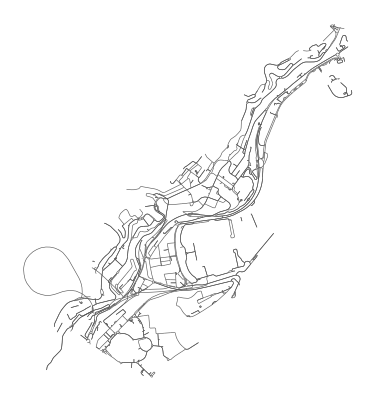

In [5]:
gdf = duckosm.edges(db)    # the driving edges as a GeoDataFrame
duckosm.show_edges(gdf)    # a map of the edges, styled by road class

## Query the edges

Each row of `<mode>.edges` is one direction of a road. `edge_id` is a `BIGINT` content hash: it stays the same after a rebuild, a cut and an export. Other data joins on it (see notebook 5).

In [6]:
import duckdb

con = duckdb.connect(str(db), read_only=True)
# the number of edges and the length of each network
con.sql("""SELECT 'driving' AS mode, count(*) AS edges, round(sum(length_m) / 1000, 1) AS km FROM driving.edges
           UNION ALL
           SELECT 'walking', count(*), round(sum(length_m) / 1000, 1) FROM walking.edges""").df()

,mode,edges,km
0,driving,2840,96.2
1,walking,11938,260.6


In [7]:
# the road classes of the driving network, by length
con.sql("""SELECT highway, count(*) AS edges, round(sum(length_m) / 1000, 1) AS km
           FROM driving.edges GROUP BY highway ORDER BY km DESC LIMIT 8""").df()

,highway,edges,km
0,residential,919,31.7
1,service,855,23.7
2,secondary,429,14.9
3,tertiary,387,12.5
4,primary,197,11.2
5,primary_link,21,1.1
6,unclassified,13,0.6
7,secondary_link,13,0.4


In [8]:
# the longest named roads, and the type of edge_id
con.sql("""SELECT name, round(sum(length_m)) AS length_m, count(*) AS edges, any_value(typeof(edge_id)) AS edge_id_type
           FROM driving.edges WHERE name IS NOT NULL GROUP BY name ORDER BY length_m DESC LIMIT 5""").df()

,name,length_m,edges,edge_id_type
0,Boulevard du Larvotto,5305.0,85,BIGINT
1,Boulevard du Jardin Exotique,3280.0,73,BIGINT
2,Avenue Princesse Grace,2576.0,86,BIGINT
3,Avenue Pasteur,2246.0,42,BIGINT
4,Tunnel Albert II,1994.0,7,BIGINT


In [9]:
con.close()